In [43]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [44]:
planets = pd.read_csv('exoplanet_data.csv', comment = "#")
planets.head()

,pl_name,hostname,default_flag,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,soltype,pl_controv_flag,...,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2,rowupdate,pl_pubdate,releasedate
0,7 CMa c,7 CMa,0,1,2,Radial Velocity,2019,Multiple Observatories,Published Confirmed,0,...,-0.03,1.564,0.252,-0.252,3.67853,0.004135,-0.004135,2024-09-13,2024-07,2024-09-13
1,7 CMa c,7 CMa,1,1,2,Radial Velocity,2019,Multiple Observatories,Published Confirmed,0,...,-0.03,1.564,0.252,-0.252,3.67853,0.004135,-0.004135,2019-10-18,2019-11,2019-10-24
2,DMPP-1 b,DMPP-1,1,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2026-03-05,2026-04,2026-03-05
3,DMPP-1 b,DMPP-1,0,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2020-01-23,2019-12,2020-01-30
4,DMPP-1 c,DMPP-1,0,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2020-01-23,2019-12,2020-01-30


In [45]:
print(planets.shape)
#the shape of my dataset is 599 by 92
print(planets.columns.to_list())
# 1) disc_facility  2) pl_orbper  3) pl_rade  4) pl_bmasse  5) sy_pnum

(599, 92)
['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum', 'discoverymethod', 'disc_year', 'disc_facility', 'soltype', 'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1', 'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1', 'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1', 'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2', 'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2', 'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2', 'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1', 'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff', 'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1', 'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2', 'st_masslim', 'st_met', 'st_meterr1', 'st_meterr2', 'st_metlim', 'st_metratio', 'st_

In [46]:
my_cols = ['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt', 'pl_bmassj']

for col in my_cols:
    print(col, col in planets.columns)

pl_name True
hostname True
discoverymethod True
st_spectype True
pl_eqt True
pl_bmassj True


In [47]:
#Table label: Planet name
#Database Column name: pl_name
#Description: Planet name most commonly used in the literature
#In my own words: The name of the planet

#Table label: Host Name
#Database Column name: hostname
#Description: Stellar name most commonly used in the literature
#In my own words: The name of the star the planet orbits

#Table label: Discovery Method
#Database Column name: discovery method
#Description: Method by which the planet was first identified
#In my own words: How they found the exoplanet initially

#Table label: Spectral type
#Database Column name: st_spectype 
#Description:Classification of the star based on their spectral characteristics following the Morgan-Keenan system
#In my own words: The classification of a star based on characteristics of its light spectrum and surface temperature

#Table label: Equilibrium Temperature [K]
#Database Column name: pl_eqt
#Description: The equilibrium temperature of the planet as modeled by a black body heated only by its host star, or for directly imaged planets, the effective temperature of the planet required to match the measured luminosity if the planet were a black body
#In my own words: The temperature a planet would reach if it depended purely on energy absorbed from the host star.

#Table label: Planet Mass or Mass*sin(i) [Jupiter Mass]
#Database Column name: pl_bmassj
#Description: Best planet mass estimate available, in order of preference: Mass, M*sin(i)/sin(i), or M*sin(i), depending on availability, and measured in Jupiter masses
#In my own words: The best estimate available for the mass of a planet, given in Jupiter masses. Some methods are only able to get a minimum mass due to the angle of the orbit, so NASA uses this mass if this is the case, and the true mass if it is known.



In [48]:
small = planets[my_cols]
small = small.dropna()
print(small)

         pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
3       DMPP-1 b     DMPP-1  Radial Velocity        F8 V   877.0   0.076362
4       DMPP-1 c     DMPP-1  Radial Velocity        F8 V  1239.0   0.030205
6       DMPP-1 d     DMPP-1  Radial Velocity        F8 V  1632.0   0.010540
8       DMPP-1 e     DMPP-1  Radial Velocity        F8 V  1314.0   0.012994
9       DMPP-2 b     DMPP-2  Radial Velocity        F5 V  1000.0   0.437000
..           ...        ...              ...         ...     ...        ...
575   WASP-185 b   WASP-185          Transit        G0 V  1160.0   0.980000
580   WASP-190 b   WASP-190          Transit     F6 IV-V  1500.0   1.000000
584   WASP-192 b   WASP-192          Transit        G0 V  1620.0   2.300000
585       XO-7 b       XO-7          Transit        G0 V  1743.0   0.709000
597  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0   6.310000

[77 rows x 6 columns]


In [49]:
#the shape is 77 x 6
#there are 77 rows and 6 colums
print(small.head()) #first five columns
print(small.tail()) #last five columns
print(small.columns.to_list())

    pl_name hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
3  DMPP-1 b   DMPP-1  Radial Velocity        F8 V   877.0   0.076362
4  DMPP-1 c   DMPP-1  Radial Velocity        F8 V  1239.0   0.030205
6  DMPP-1 d   DMPP-1  Radial Velocity        F8 V  1632.0   0.010540
8  DMPP-1 e   DMPP-1  Radial Velocity        F8 V  1314.0   0.012994
9  DMPP-2 b   DMPP-2  Radial Velocity        F5 V  1000.0   0.437000
         pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
575   WASP-185 b   WASP-185          Transit        G0 V  1160.0      0.980
580   WASP-190 b   WASP-190          Transit     F6 IV-V  1500.0      1.000
584   WASP-192 b   WASP-192          Transit        G0 V  1620.0      2.300
585       XO-7 b       XO-7          Transit        G0 V  1743.0      0.709
597  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0      6.310
['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt', 'pl_bmassj']


In [50]:
small['discoverymethod'].value_counts()

discoverymethod
Transit            62
Radial Velocity    13
Imaging             2
Name: count, dtype: int64

In [51]:
#there are 62 found via transit method, 13 found through radial velocity, and 2 found through imaging
# transit: the transit method is when you detect an exoplanet by measuring a periodic dip in a star's brightness when a planet passes in front of it
# radial velocity: the "wobble" method -- done by measuring the gravitational influence a planet has on a star
# imaging: Using actual pictures to detect planets

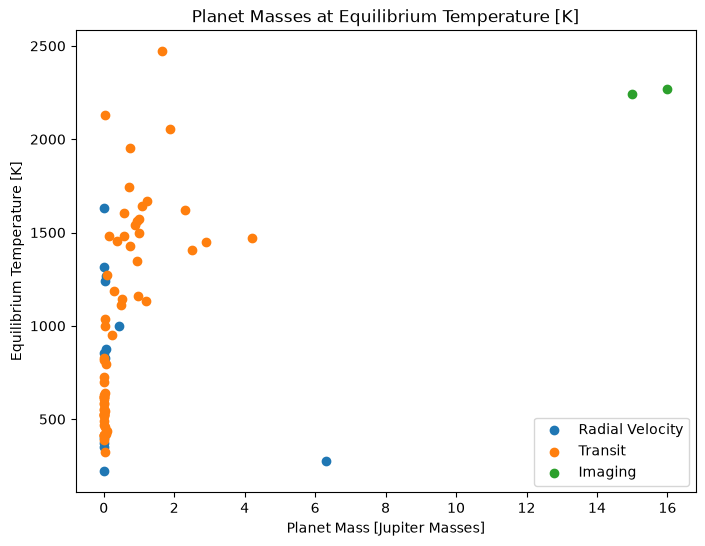

In [52]:
plt.figure(figsize= (8,6))

for method in small['discoverymethod'].unique():
    subset = small[small['discoverymethod'] == method]
    plt.scatter(subset['pl_bmassj'], subset['pl_eqt'], label= method)

plt.title('Planet Masses at Equilibrium Temperature [K]')
plt.xlabel('Planet Mass [Jupiter Masses]')
plt.ylabel('Equilibrium Temperature [K]')
plt.legend()
plt.show()

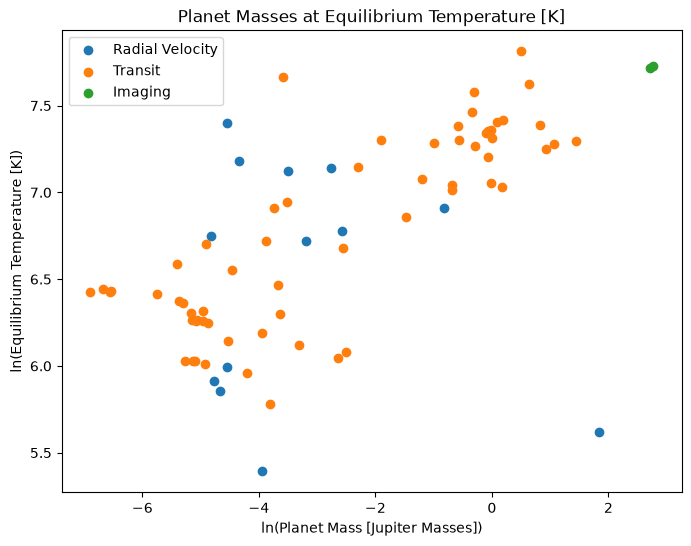

In [53]:
plt.figure(figsize= (8,6))

for method in small['discoverymethod'].unique():
    subset = small[small['discoverymethod'] == method]
    plt.scatter(np.log(subset['pl_bmassj']), np.log(subset['pl_eqt']), label=method)

plt.title('Planet Masses at Equilibrium Temperature [K]')
plt.xlabel('ln(Planet Mass [Jupiter Masses])')
plt.ylabel('ln(Equilibrium Temperature [K])')
plt.legend()
plt.show()

In [54]:
#Based on the plot, exoplanets found by the imaging method are more likely to be massive

In [55]:
heavy = small[small['pl_bmassj'] > 5]
i = heavy ['pl_eqt'].idxmin()
heavy.loc[i]

pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 597, dtype: object

In [56]:
# Name: eps Ind A b
# Index: 597
# Equilibrium temperature: 275.0 K
# Mass: 6.31 Jupiter masses
# Host star spectral type: K5 V. It's a main-sequence star like the Sun (the "V"),
#   but it's a K star, so it's a bit cooler, smaller, and more orange than the Sun,
#   which is a G2 V star. So it's similar to the Sun, but not exactly sun-like.

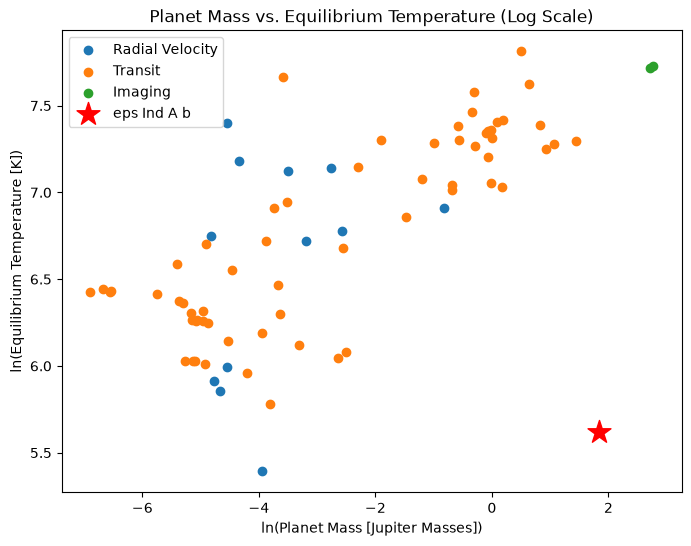

In [57]:
plt.figure(figsize=(8, 6))

for method in small['discoverymethod'].unique():
    subset = small[small['discoverymethod'] == method]
    plt.scatter(np.log(subset['pl_bmassj']), np.log(subset['pl_eqt']), label=method)

# Highlight the coldest planet with mass > 5 Jupiter masses
coldest = heavy.loc[i]
plt.scatter(np.log(coldest['pl_bmassj']), np.log(coldest['pl_eqt']),
            color='red', marker='*', s=300, label=coldest['pl_name'])

plt.title('Planet Mass vs. Equilibrium Temperature (Log Scale)')
plt.xlabel('ln(Planet Mass [Jupiter Masses])')
plt.ylabel('ln(Equilibrium Temperature [K])')
plt.legend()
plt.show()

In [58]:
#--4.5--
# the title is A temperate super-Jupiter imaged with JWST in the mid-infrared
#Almost every planet that’s been directly photographed is young. Of the roughly 25 imaged before this, all are younger than 500Myr and all but 6 are younger than 100Myr. This team used JWST to photograph a giant planet around Eps Ind A, a K5V star of roughly solar age. Earlier studies had predicted a planet there from the star’s wobble, and JWST’s images are consistent with these radial and astrometric measurements, but inconsistent with the previously claimed planet properties. The planet has temperature ~275K, and it was surprisingly faint at shorter infrared wavelengths, which the authors think could mean a high metallicity, high carbon-to-oxygen ratio planet. Its temperature also fits theoretical thermal evolution models, which are previously untested at this temperature range.
# Yes, the planet matches
#What's special about it : It’s one of the coldest exoplanets ever directly imaged, around 2°C, which is crazy cold for a planet we can actually see. It’s also really close to us, only about 12 light-years away. The researchers said it’s more similar to Jupiter than any other planet that’s been imaged so far, and it’s old, since its star is about the Sun’s age, while most imaged planets are still young and hot.
#Does mass and temperature match: The temperature matches exactly: my data says 275 K and so does the paper. The mass is really close: my data says 6.31 Jupiter masses and the paper says a little over 6, so that difference is probably just uncertainty in the measurement. One thing that’s different is that my dataset says it was discovered by radial velocity, but the paper is about imaging it. That’s because it was first detected from the wobble of its star using radial velocity, and then JWST imaged it later. The paper also says the earlier radial velocity studies underestimated the planet’s mass and how far it is from its star.